# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 1: Predict the Output

---

### **Problem Statement**
A quantum circuit can produce different measurement outcomes depending on the gates applied to a qubit.
Your task is to predict the output of simple quantum circuits before executing them and then compare your prediction with the actual measurement results.

### **Design Constraints**
- Use exactly **1 qubit**.
- Include **measurement**.
- Use only the gates introduced in the workshop ($X$, $H$).
- Be created and executed using **Qiskit**.
- Use **100 shots** for each experiment.


## Step 1: Environment Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

# Initialize AerSimulator backend
backend = AerSimulator()
SHOTS = 100
print(f"AerSimulator backend initialized. Shots set to: {SHOTS}")


AerSimulator backend initialized. Shots set to: 100


## Investigation 1: Circuit A — Single X Gate

### **Think Before You Run (Prediction for Circuit A)**
- **Initial State**: The qubit is prepared in state $|0\rangle$.
- **Applied Gate**: The Pauli-$X$ gate acts as the quantum NOT gate (bit-flip):
  $$X |0\rangle = |1\rangle$$
- **Expected Measurement Outcome**: 
  Since the state is deterministically $|1\rangle$, measurement in the computational $Z$-basis will yield output **`1`** with **100% probability**.
- **Prediction for 100 Shots**: 
  We expect exactly **100 counts for outcome `1`** and **0 counts for outcome `0`**.


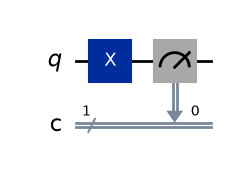

In [2]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_a = QuantumCircuit(1, 1)

# 2. Apply an X gate
qc_a.x(0)

# 3. Measure the qubit
qc_a.measure(0, 0)

# Draw the circuit
qc_a.draw('mpl')


Circuit A Measurement Results (100 shots): {'1': 100}


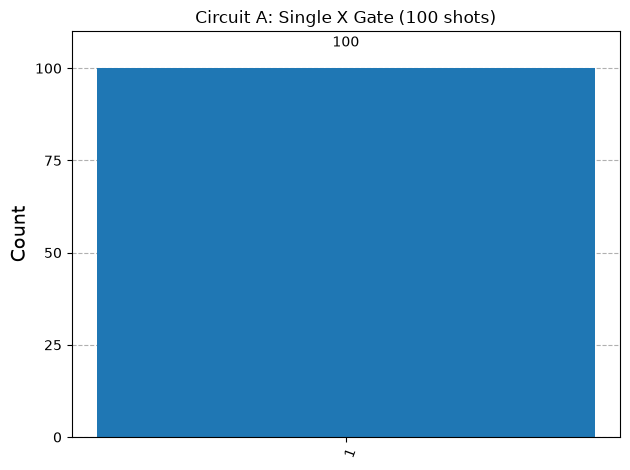

In [3]:
# 4. Execute Circuit A for 100 shots
result_a = backend.run(qc_a, shots=SHOTS).result()
counts_a = result_a.get_counts()

print("Circuit A Measurement Results (100 shots):", counts_a)

# Display histogram
plot_histogram(counts_a, title="Circuit A: Single X Gate (100 shots)")


### **Circuit A: Comparison of Prediction vs Actual Results**
- **Predicted**: 100% outcome `1` (100 counts)
- **Actual**: 100% outcome `1` (`counts = {'1': 100}`)
- **Conclusion**: The prediction perfectly matches the actual measurement. The $X$ gate flipped $|0\rangle$ to $|1\rangle$.


## Investigation 2: Circuit B — Two X Gates

### **Think Before You Run (Prediction for Circuit B)**
- **Initial State**: The qubit starts in $|0\rangle$.
- **Applied Gates**: Two consecutive $X$ gates:
  $$X(X|0\rangle) = X|1\rangle = |0\rangle$$
  Because $X^2 = I$ (the identity operator), the second $X$ gate inverts the operation of the first $X$ gate.
- **Expected Measurement Outcome**: 
  The qubit returns to the ground state $|0\rangle$. Measurement will yield outcome **`0`** with **100% probability**.
- **Prediction for 100 Shots**: 
  We expect exactly **100 counts for outcome `0`** and **0 counts for outcome `1`**.


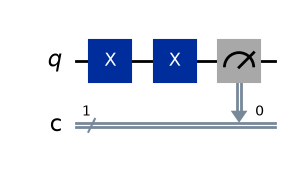

In [4]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_b = QuantumCircuit(1, 1)

# 2. Apply two X gates
qc_b.x(0)
qc_b.x(0)

# 3. Measure the qubit
qc_b.measure(0, 0)

# Draw the circuit
qc_b.draw('mpl')


Circuit B Measurement Results (100 shots): {'0': 100}


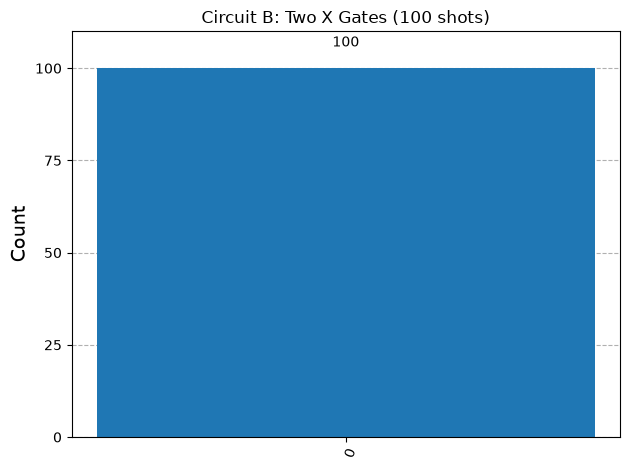

In [5]:
# 4. Execute Circuit B for 100 shots
result_b = backend.run(qc_b, shots=SHOTS).result()
counts_b = result_b.get_counts()

print("Circuit B Measurement Results (100 shots):", counts_b)

# Display histogram
plot_histogram(counts_b, title="Circuit B: Two X Gates (100 shots)")


### **Circuit B: Comparison of Prediction vs Actual Results**
- **Predicted**: 100% outcome `0` (100 counts)
- **Actual**: 100% outcome `0` (`counts = {'0': 100}`)
- **Conclusion**: The prediction perfectly matches the actual measurement. Two successive NOT operations preserve the original state ($X \cdot X = I$).


## Investigation 3: Circuit C — Single H Gate

### **Think Before You Run (Prediction for Circuit C)**
- **Initial State**: The qubit starts in $|0\rangle$.
- **Applied Gate**: The Hadamard ($H$) gate creates an equal superposition:
  $$H |0\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle = |+\rangle$$
- **Measurement Probabilities**:
  $$P(0) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$$
  $$P(1) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$$
- **Will Circuit C always produce the same measurement result?**
  **No.** Unlike Circuits A and B, which are in basis states, Circuit C places the qubit in an equal quantum superposition. When measured, the wavefunction collapses probabilistically to either `0` or `1`.
- **Prediction for 100 Shots**: 
  Across 100 shots, we expect roughly **50 counts of `0` and 50 counts of `1`**, subject to small statistical fluctuations (shot noise).


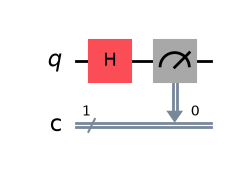

In [6]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_c = QuantumCircuit(1, 1)

# 2. Apply an H gate
qc_c.h(0)

# 3. Measure the qubit
qc_c.measure(0, 0)

# Draw the circuit
qc_c.draw('mpl')


Circuit C Measurement Results (100 shots): {'1': 50, '0': 50}


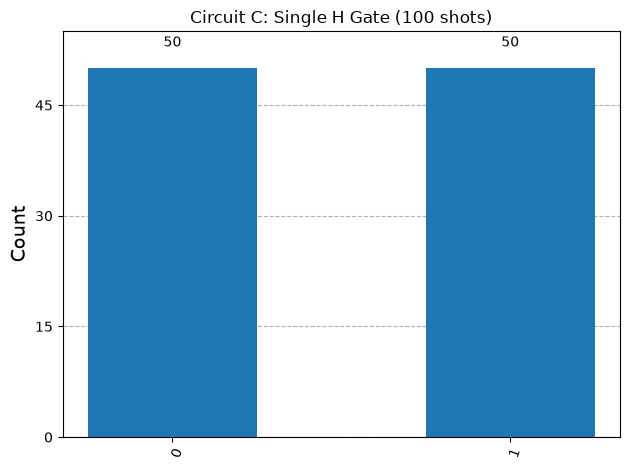

In [7]:
# 4. Execute Circuit C for 100 shots
result_c = backend.run(qc_c, shots=SHOTS).result()
counts_c = result_c.get_counts()

print("Circuit C Measurement Results (100 shots):", counts_c)

# Display histogram
plot_histogram(counts_c, title="Circuit C: Single H Gate (100 shots)")


### **Circuit C: Comparison of Prediction vs Actual Results**
- **Predicted**: Approximately equal distribution (~50 counts of `0` and ~50 counts of `1`).
- **Actual**: Observed distribution closely mirrors 50/50, demonstrating true probabilistic quantum superposition and wavefunction collapse.


## Step 5: Side-by-Side Comparison of All Three Circuits

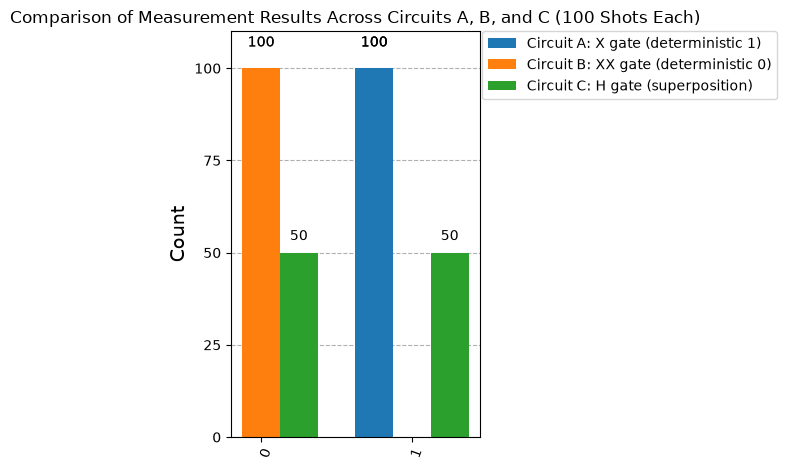

In [8]:
# Display all three circuits in a single comparison histogram
plot_histogram(
    [counts_a, counts_b, counts_c],
    legend=['Circuit A: X gate (deterministic 1)', 'Circuit B: XX gate (deterministic 0)', 'Circuit C: H gate (superposition)'],
    title='Comparison of Measurement Results Across Circuits A, B, and C (100 Shots Each)'
)


## Summary & Answers to Workshop Questions

| Circuit | Gates Applied | Theoretical State | Predicted Outcome | Actual Result (100 shots) | Behavior |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | $X$ | $|1\rangle$ | Deterministic `1` (100%) | 100% `1` | Deterministic bit flip |
| **Circuit B** | $X, X$ | $|0\rangle$ | Deterministic `0` (100%) | 100% `0` | Identity self-inverse |
| **Circuit C** | $H$ | $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$ | Probabilistic 50% `0` / 50% `1` | ~50% `0`, ~50% `1` | Quantum superposition |

### **Think Before You Run Questions Answered:**
1. **What will happen after applying one X gate?**  
   The qubit transitions from $|0\rangle$ to $|1\rangle$. The measurement yields outcome `1` with 100% certainty.
2. **What will happen after applying two X gates?**  
   The second $X$ gate reverses the first ($X^2 = I$), returning the qubit to $|0\rangle$. The measurement yields outcome `0` with 100% certainty.
3. **What do you expect after applying an H gate?**  
   The qubit enters an equal superposition state $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$, producing equal 50% probabilities of measuring `0` or `1`.
4. **Will Circuit C always produce the same measurement result?**  
   **No**, each single shot is fundamentally non-deterministic due to quantum measurement collapse. Over 100 shots, both `0` and `1` are observed in roughly equal proportions.
